# MPS example: software vs hardware results

This notebook checks the hardware (FPGA) inference results of the 4-feature MPS model
against the software model:

1. **SW/HW comparison:** element-wise differences between the hardware outputs and the full-precision software outputs.
2. **Accuracy:** classification accuracy of both against the true labels.
3. **ROC-AUC:** one-vs-rest ROC-AUC, overall and per class.

Run it from this folder (`examples/mps`). Files used:

| File | Contents |
|---|---|
| `dataset/software_full_precision_results.txt` | software model outputs, 5 per sample |
| `dataset/y_N4.npy` | one-hot labels, shape (1000, 5) |
| `hw_results/*.txt` | hardware outputs, 5 per sample |

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc

## Configuration

Set `HW_RESULTS` to the hardware results file to check. To check your own run, point it at the
C-sim or on-board results file the tool wrote.

In [2]:
DATASET_DIR = Path("dataset")
HW_RESULTS = Path("hw_results/mps4_166_hwresults.txt")  # or hw_results/mps4_168_hwresults.txt

SW_RESULTS = DATASET_DIR / "software_full_precision_results.txt"
LABELS = DATASET_DIR / "y_N4.npy"

## Helpers

The MPS output for each class is a raw score: the predicted class is the largest score, and
a softmax turns the scores into probabilities for the ROC curves.

In [3]:
def predict(out):
    """MPS: the predicted class is the largest raw output."""
    return out.argmax(axis=1)


def scores_to_probs(out):
    """MPS: softmax of the raw outputs."""
    e = np.exp(out - out.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

N_CLASSES = 5

# ROC curve colours, one per class in a fixed order
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]


def load_results(sw_file, hw_file, labels_file):
    """Load software outputs, hardware outputs and labels as (N, 5), (N, 5), (N,)."""
    sw_file, hw_file = Path(sw_file), Path(hw_file)
    sw = np.load(sw_file) if sw_file.suffix == ".npy" else np.loadtxt(sw_file)
    sw = sw.astype(np.float64).reshape(-1, N_CLASSES)
    hw = np.loadtxt(hw_file).reshape(-1, N_CLASSES)
    y_true = np.load(labels_file).argmax(axis=1)  # one-hot -> class index

    n = min(len(sw), len(hw), len(y_true))  # hardware runs may cover fewer samples
    print(f"software: {sw.shape[0]} samples, hardware: {hw.shape[0]} samples, labels: {y_true.shape[0]}")
    print(f"comparing the first {n} samples")
    return sw[:n], hw[:n], y_true[:n]


def infer_frac_bits(x, max_bits=32):
    """Fractional bits of the hardware fixed-point type, read from the outputs themselves:
    the smallest f for which every value is a multiple of 2**-f."""
    for f in range(max_bits + 1):
        scaled = x * 2.0**f
        if np.all(np.abs(scaled - np.round(scaled)) < 1e-9):
            return f
    return None


def compare_outputs(sw, hw):
    """Element-wise difference statistics between software and hardware outputs."""
    diff = (sw - hw).ravel()
    frac_bits = infer_frac_bits(hw)
    print(f"fractional bits (from hw outputs): {frac_bits}  ->  resolution 2^-{frac_bits} = {2.0**-frac_bits:.5e}")
    print(f"mean difference (sw - hw):         {diff.mean():.6e}")
    print(f"std of differences:                {diff.std():.6e}")
    print(f"RMSE:                              {np.sqrt(np.mean(diff**2)):.6e}")
    print(f"max |difference|:                  {np.abs(diff).max():.6e}")


def plot_sw_hw(sw, hw, title="SW/HW Output Comparison", lim=None, save_as=None):
    """Software vs hardware outputs, one point per output value.
    `lim` zooms both axes to [-lim, lim]; `save_as` writes the figure at 300 dpi."""
    hw_flat, sw_flat = hw.ravel(), sw.ravel()
    diff = sw_flat - hw_flat
    frac_bits = infer_frac_bits(hw_flat)

    plt.figure(figsize=(8, 6), dpi=120)
    plt.scatter(hw_flat, sw_flat, color="green", alpha=0.8, edgecolor="g",
                label=f"Outputs ({hw.shape[0]} samples × {hw.shape[1]} classes)")

    # Identity line (y = x): points on it are exact sw/hw matches
    if lim is None:
        lo, hi = min(sw_flat.min(), hw_flat.min()), max(sw_flat.max(), hw_flat.max())
    else:
        lo, hi = -lim, lim
        plt.xlim(lo, hi)
        plt.ylim(lo, hi)
    plt.plot([lo, hi], [lo, hi], alpha=0.5, color="red", linestyle="-", linewidth=2, label="y = x (exact match)")

    plt.xlabel("Hardware output (fixed point)", fontsize=16)
    plt.ylabel("Software output (floating point)", fontsize=16)
    plt.title(title, fontsize=18)

    # Summary entries in the legend
    plt.plot([], [], " ", label=f"Fractional bits: {frac_bits}")
    plt.plot([], [], " ", label=f"Resolution: 2$^{{-{frac_bits}}}$ = {2.0**-frac_bits:.5e}")
    plt.plot([], [], " ", label=f"SD of SW − HW: {diff.std():.5e}")
    plt.plot([], [], " ", label=f"Max |SW − HW|: {np.abs(diff).max():.5e}")
    plt.legend(fontsize=11, loc="upper left")
    plt.grid(True, linestyle="--", linewidth=0.8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=300)
    plt.show()


def accuracy_report(sw, hw, y_true):
    pred_sw, pred_hw = predict(sw), predict(hw)
    print(f"software accuracy:            {np.mean(pred_sw == y_true):.4f}")
    print(f"hardware accuracy:            {np.mean(pred_hw == y_true):.4f}")
    print(f"sw/hw prediction agreement:   {np.mean(pred_sw == pred_hw):.4f}")


def roc_report(sw, hw, y_true):
    """One-vs-rest ROC-AUC for software and hardware, overall and per class."""
    rows = {}
    for name, out in (("software", sw), ("hardware", hw)):
        probs = scores_to_probs(out)
        rows[name] = (
            roc_auc_score(y_true, probs, multi_class="ovr", average="macro"),
            roc_auc_score(y_true, probs, multi_class="ovr", average="weighted"),
            roc_auc_score(np.eye(N_CLASSES)[y_true], probs, average=None),
        )
    print(f"{'':10s}{'software':>10s}{'hardware':>10s}")
    print(f"{'macro':10s}{rows['software'][0]:10.4f}{rows['hardware'][0]:10.4f}")
    print(f"{'weighted':10s}{rows['software'][1]:10.4f}{rows['hardware'][1]:10.4f}")
    for c in range(N_CLASSES):
        print(f"{'class ' + str(c):10s}{rows['software'][2][c]:10.4f}{rows['hardware'][2][c]:10.4f}")


def plot_roc(out, y_true, title="ROC Curves (one-vs-rest)", save_as=None):
    """Per-class one-vs-rest ROC curves, styled to match plot_sw_hw.
    `save_as` writes the figure at 300 dpi."""
    probs = scores_to_probs(out)
    y_bin = np.eye(N_CLASSES)[y_true]

    plt.figure(figsize=(8, 6), dpi=120)
    for k in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, k], probs[:, k])
        plt.plot(fpr, tpr, linewidth=2, color=COLORS[k], label=f"Class {k} (AUC = {auc(fpr, tpr):.3f})")

    # Micro-average: every (sample, class) pair pooled into one binary problem
    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
    plt.plot(fpr, tpr, linewidth=2, linestyle=":", color="black",
             label=f"Micro-average (AUC = {auc(fpr, tpr):.3f})")

    # Chance diagonal, drawn like the y = x line of the SW/HW plot but in grey
    plt.plot([0, 1], [0, 1], alpha=0.5, color="grey", linestyle="--", linewidth=2, label="Chance (AUC = 0.500)")

    plt.xlim(0, 1)
    plt.ylim(0, 1.01)
    plt.xlabel("False positive rate", fontsize=16)
    plt.ylabel("True positive rate", fontsize=16)
    plt.title(title, fontsize=18)

    # Summary entries in the legend
    plt.plot([], [], " ", label=f"Macro AUC: {roc_auc_score(y_true, probs, multi_class='ovr', average='macro'):.4f}")
    plt.plot([], [], " ", label=f"Weighted AUC: {roc_auc_score(y_true, probs, multi_class='ovr', average='weighted'):.4f}")
    plt.legend(fontsize=11, loc="lower right")
    plt.grid(True, linestyle="--", linewidth=0.8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=300)
    plt.show()

## Load results

In [4]:
sw, hw, y_true = load_results(SW_RESULTS, HW_RESULTS, LABELS)

software: 1000 samples, hardware: 992 samples, labels: 1000
comparing the first 992 samples


## SW/HW comparison

Points on the dashed line are outputs where hardware and software agree. Large outliers
usually mean the output was saturated: its software value is outside the range the
hardware's fixed-point type can represent.

In [5]:
compare_outputs(sw, hw)

fractional bits (from hw outputs): 10  ->  resolution 2^-10 = 9.76562e-04
mean difference (sw - hw):         4.378140e-02
std of differences:                8.096615e-01
RMSE:                              8.108443e-01
max |difference|:                  3.004795e+01


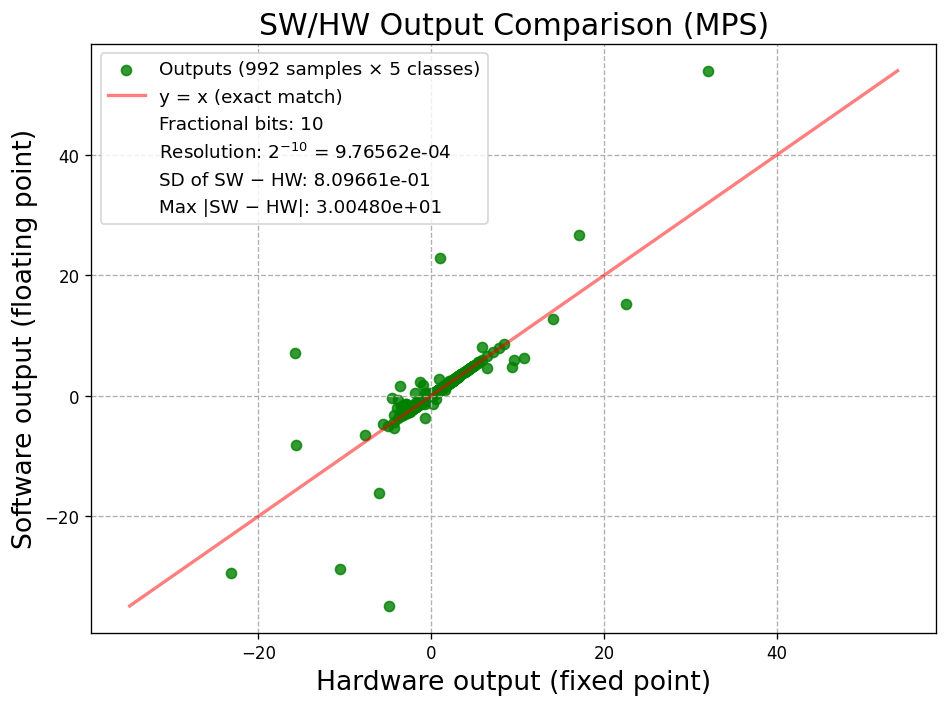

In [6]:
plot_sw_hw(sw, hw, "SW/HW Output Comparison (MPS)")

Zoomed in on the bulk of the outputs:

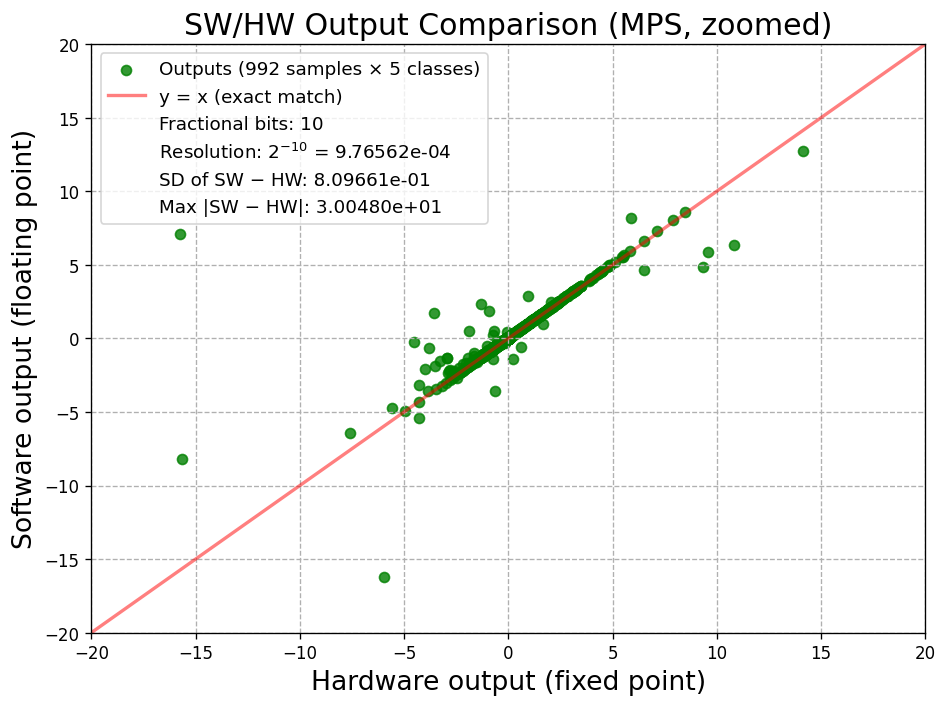

In [7]:
plot_sw_hw(sw, hw, "SW/HW Output Comparison (MPS, zoomed)", lim=20)

## Accuracy

In [8]:
accuracy_report(sw, hw, y_true)

software accuracy:            0.7440
hardware accuracy:            0.7419
sw/hw prediction agreement:   0.9798


## ROC-AUC (one-vs-rest)

In [9]:
roc_report(sw, hw, y_true)

            software  hardware
macro         0.8814    0.8792
weighted      0.8823    0.8800
class 0       0.9033    0.8982
class 1       0.8469    0.8449
class 2       0.9319    0.9296
class 3       0.8481    0.8461
class 4       0.8767    0.8772


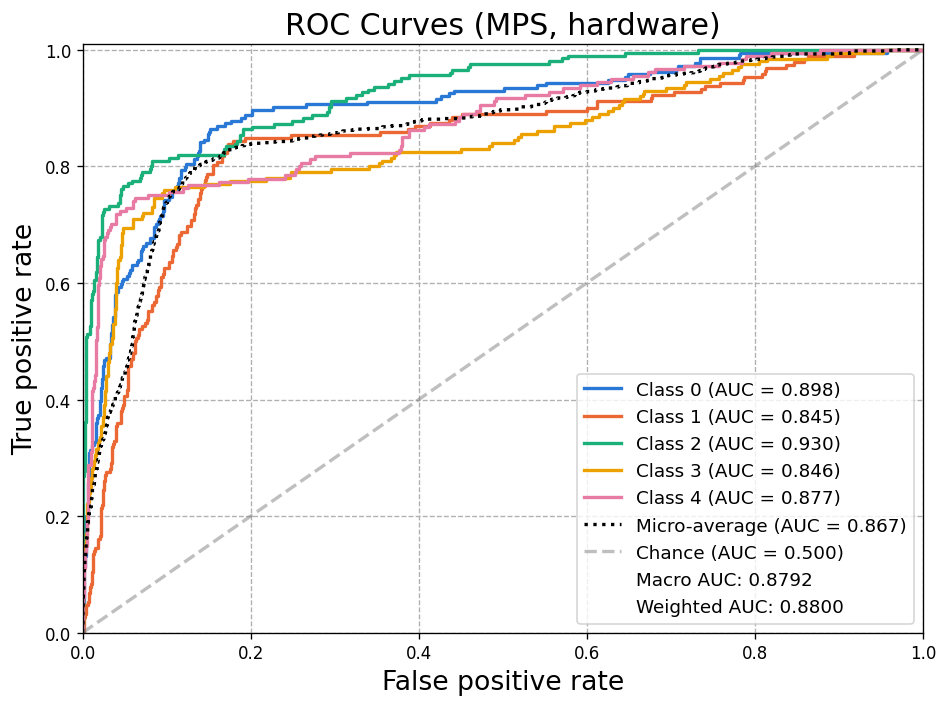

In [10]:
plot_roc(hw, y_true, "ROC Curves (MPS, hardware)")